In [14]:
#Comenzaremos pasando nuestros datos a un DataFrame de pandas
import pandas as pd
df = pd.read_csv('C:\\Users\\yetla\\Downloads\\BasesUnidas.csv')

In [15]:
#En caso de hayan datos nulos los eliminaremos
df = df.dropna()
df.isnull().sum()

Fecha_extraccion    0
Hora_extraccion     0
Origen              0
Destino             0
Fecha_salida        0
Hora_salida         0
Precio Sin TUA      0
Aerolinea           0
kilometros          0
Disponibilidad      0
Ruta                0
Aerolinea.1         0
Dias_anticipados    0
Hora_vuelo          0
dtype: int64

In [16]:
#Cambiaremos el nombre de la columna Aerolinea.1
df = df.rename(columns={'Aerolinea.1':'Aerolinea'})

In [17]:
#Ahora convertiremos la columna 'Fecha_extraccion' a tipo datetime
import locale
locale.setlocale(locale.LC_TIME, "es_MX")  # O "es_MX" en Windows

df['Fecha_extraccion'] = pd.to_datetime(df['Fecha_extraccion'], format='%A, %d de %B de %Y')
# Ahora Fecha_salida
df['Fecha_salida'] = pd.to_datetime(df['Fecha_salida'], format='%A, %d de %B de %Y')
#Y la aerolinea a tipo categoria
df['Aerolinea'] = df['Aerolinea'].astype('category')
# Convertir Hora_extraccion a float
df['Hora_extraccion'] = pd.to_datetime(df['Hora_extraccion'], format="%H:%M:%S").dt.hour + \
                        pd.to_datetime(df['Hora_extraccion'], format="%H:%M:%S").dt.minute / 60

# Convertir Hora_salida a float
df['Hora_salida'] = pd.to_datetime(df['Hora_salida'], format="%H:%M:%S").dt.hour + \
                    pd.to_datetime(df['Hora_salida'], format="%H:%M:%S").dt.minute / 60
                    
#Por ultimo cambiamos la columna kilometros a tipo numérico
df['kilometros'] = df['kilometros'].str.replace('km','',regex=False)\
                                   .str.replace(' ','',regex=False)\
                                   .str.replace(',','',regex=False)\
                                   .astype(float)

In [5]:
#Eliminamos columnas duplicadas si es que existen
df = df.loc[:, ~df.columns.duplicated()]

In [18]:
#Pasaremos al modelado, dado que tanto XGBoost como Random Forest necesitan que los datos esten en categorías numéricas
# Entonces convertiremos las variables  destino y  ruta  a variables numéricas usando One-Hot Encoding 
df['Destino'] = df['Destino'].astype('category')
df['Disponibilidad'] = df['Disponibilidad'].astype('category')
df['Ruta'] = df['Ruta'].astype('category')
df = pd.get_dummies(df, columns=['Destino', 'Aerolinea', 'Disponibilidad', 'Ruta'], drop_first=False)

In [19]:
#Separemos X y Y y dividiremos los datos en entrenamiento y prueba
# Variable objetivo
y = df['Precio Sin TUA']

# Variables predictoras
X = df[[    
    'Hora_extraccion',
    'Hora_salida',
    'kilometros',
    'Dias_anticipados',
    'Destino_Guadalajara (GDL)',
    'Destino_Tuxtla Gutiérrez (TGZ)',
    'Destino_Veracruz (VER)',
    'Destino_Chihuahua (CUU)',
    'Aerolinea_VivaAerobus',
    'Aerolinea_Aeroméxico',
    'Ruta_MEX-GDL',
    'Ruta_MEX-TGZ',
    'Ruta_MEX-VER',
    'Ruta_MEX-CUU'
]]

# Convertir booleanos a int, columna por columna
bool_cols = X.select_dtypes(include='bool').columns
for col in bool_cols:
    X[col] = X[col].astype(int)

C:\Users\yetla\AppData\Local\Temp\ipykernel_124020\2656662058.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[col] = X[col].astype(int)
C:\Users\yetla\AppData\Local\Temp\ipykernel_124020\2656662058.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[col] = X[col].astype(int)
C:\Users\yetla\AppData\Local\Temp\ipykernel_124020\2656662058.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the 

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

# Lista de destinos y su columna dummy
destinos = {
    'Guadalajara (GDL)': 'Destino_Guadalajara (GDL)',
    'Tuxtla Gutiérrez (TGZ)': 'Destino_Tuxtla Gutiérrez (TGZ)',
    'Veracruz (VER)': 'Destino_Veracruz (VER)',
    'Chihuahua (CUU)': 'Destino_Chihuahua (CUU)'
}

modelos = {}
resultados = {}

for nombre_dest, col_dummy in destinos.items():

    # Filtrar el dataset SOLO para ese destino
    df_dest = df[df[col_dummy] == 1]

    # Definir X y y SOLO de ese destino
    X_dest = df_dest[[    
        'Hora_extraccion',
        'Hora_salida',
        'kilometros',
        'Dias_anticipados',
        'Aerolinea_VivaAerobus',
        'Aerolinea_Aeroméxico',
        
    ]]

    y_dest = df_dest['Precio Sin TUA']

    # Separar en train/test
    X_train, X_test, y_train, y_test = train_test_split(
        X_dest, y_dest, test_size=0.2, random_state=42
    )

    # Entrenar modelo específico para ese destino
    modelo = RandomForestRegressor()
    modelo.fit(X_train, y_train)

    # Guardar modelo y resultados
    modelos[nombre_dest] = modelo
    resultados[nombre_dest] = modelo.predict(X_test)

    print(f"✔ Modelo entrenado para: {nombre_dest}")


✔ Modelo entrenado para: Guadalajara (GDL)
✔ Modelo entrenado para: Tuxtla Gutiérrez (TGZ)
✔ Modelo entrenado para: Veracruz (VER)
✔ Modelo entrenado para: Chihuahua (CUU)


In [25]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

metricas = {}

for nombre_dest, modelo in modelos.items():

    # Recuperamos el dataset filtrado por destino
    col_dummy = destinos[nombre_dest]
    df_dest = df[df[col_dummy] == 1]

    # Variables predictoras para ese destino (las mismas usadas para entrenar)
    X_dest = df_dest[[    
        'Hora_extraccion',
        'Hora_salida',
        'kilometros',
        'Dias_anticipados',
        'Aerolinea_VivaAerobus',
        'Aerolinea_Aeroméxico'
    ]]

    # Variable objetivo
    y_dest = df_dest['Precio Sin TUA']

    # Hacemos predicciones sobre TODO el dataset del destino
    y_pred = modelo.predict(X_dest)

    # Cálculo de métricas
    mae = mean_absolute_error(y_dest, y_pred)
    rmse = np.sqrt(mean_squared_error(y_dest, y_pred))
    r2 = r2_score(y_dest, y_pred)

    # Guardamos métricas
    metricas[nombre_dest] = {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

# MOSTRAR RESULTADOS
print("========= MÉTRICAS POR DESTINO =========\n")
for destino, vals in metricas.items():
    print(f"--- {destino} ---")
    print(f"MAE : {vals['MAE']}")
    print(f"RMSE: {vals['RMSE']}")
    print(f"R²  : {vals['R2']}\n")


========= MÉTRICAS POR DESTINO =========

--- Guadalajara (GDL) ---
MAE : 1.3390277777777786
RMSE: 7.527074280370975
R²  : 0.9999003180356629

--- Tuxtla Gutiérrez (TGZ) ---
MAE : 8.17704576976421
RMSE: 27.208791032152558
R²  : 0.9998631331862421

--- Veracruz (VER) ---
MAE : 10.987717842323645
RMSE: 98.82809855871098
R²  : 0.8362485651541844

--- Chihuahua (CUU) ---
MAE : 6.231300138312581
RMSE: 40.40999547172575
R²  : 0.9987000993400159



In [22]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
import numpy as np

# Lista de las columnas de destino ya creadas en tu dataframe
destinos = [
    'Destino_Guadalajara (GDL)',
    'Destino_Tuxtla Gutiérrez (TGZ)',
    'Destino_Veracruz (VER)',
    'Destino_Chihuahua (CUU)'
]

for destino in destinos:
    print("\n==============================")
    print(f"   MODELO XGBOOST PARA: {destino}")
    print("==============================")

    # Filtrar X y y usando únicamente filas del destino correspondiente
    mask = df[destino] == 1
    X_d = X[mask]
    y_d = y[mask]

    # Dividir en entrenamiento y prueba
    X_train, X_test, y_train, y_test = train_test_split(
        X_d, y_d, test_size=0.2, random_state=42
    )

    # Modelo XGBoost
    modelo = XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42
    )

    # Entrenar
    modelo.fit(X_train, y_train)

    # Predicciones
    y_pred = modelo.predict(X_test)

    # Métricas
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    # Imprimir métricas
    print(f"MAE:  {mae}")
    print(f"RMSE: {rmse}")
    print(f"R2:   {r2}")



   MODELO XGBOOST PARA: Destino_Guadalajara (GDL)
MAE:  2.742402818467882
RMSE: 8.609874216134052
R2:   0.9998701560566915

   MODELO XGBOOST PARA: Destino_Tuxtla Gutiérrez (TGZ)
MAE:  16.81953293372845
RMSE: 56.0974650163663
R2:   0.9994057379376892

   MODELO XGBOOST PARA: Destino_Veracruz (VER)
MAE:  33.851034651131464
RMSE: 216.42305012030891
R2:   0.5219396203075447

   MODELO XGBOOST PARA: Destino_Chihuahua (CUU)
MAE:  8.557093547952586
RMSE: 25.02970599951311
R2:   0.9994929004058496


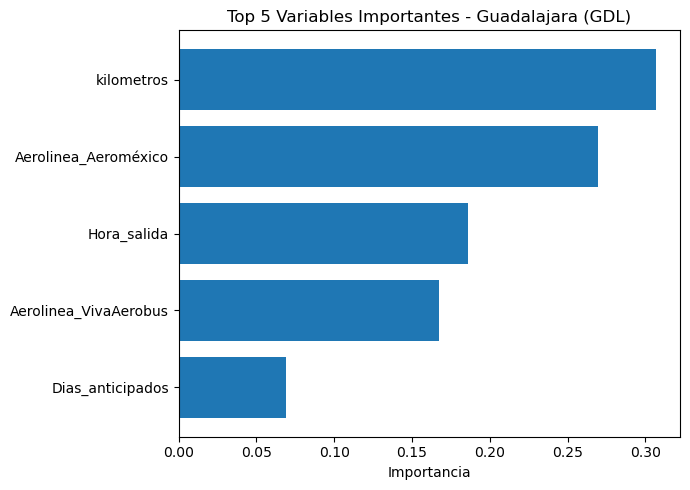

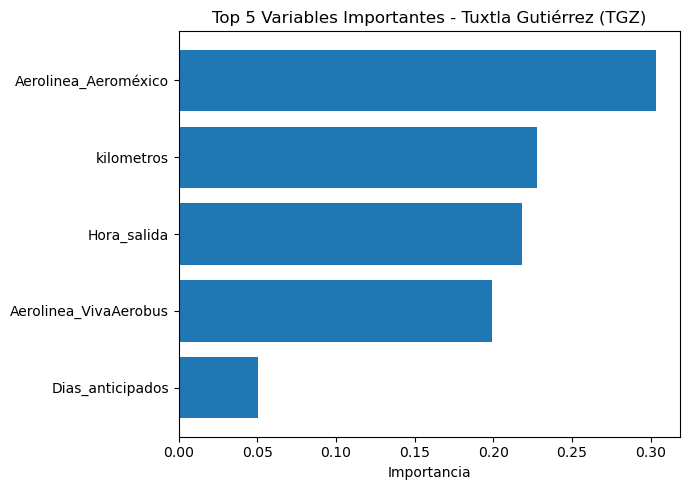

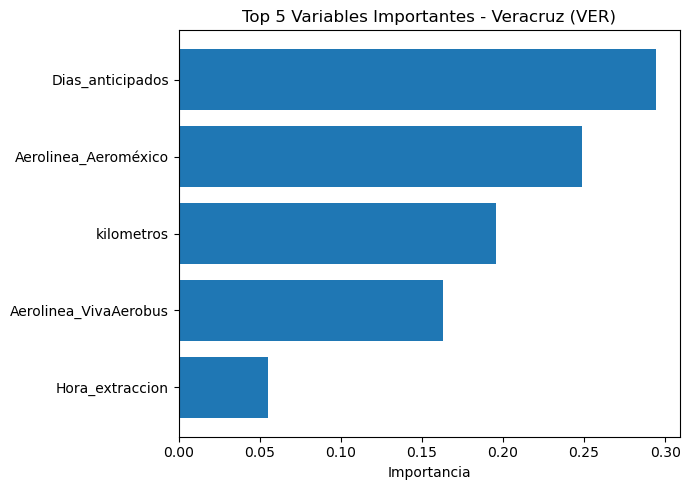

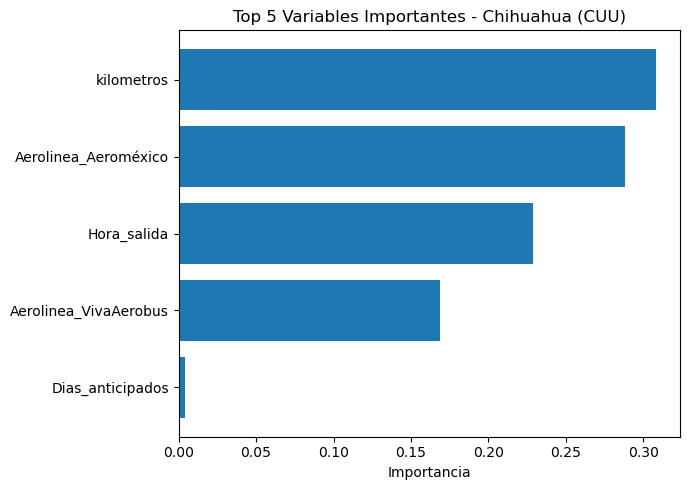

In [27]:
import matplotlib.pyplot as plt
import numpy as np

# Variables predictoras utilizadas
columnas_X = [
    'Hora_extraccion',
    'Hora_salida',
    'kilometros',
    'Dias_anticipados',
    'Aerolinea_VivaAerobus', 
    'Aerolinea_Aeroméxico'
    
]

for nombre_dest, modelo in modelos.items():

    importancias = modelo.feature_importances_
    
    # Convertir a array y ordenar top 5
    indices_top5 = np.argsort(importancias)[-5:][::-1]
    vars_top5 = [columnas_X[i] for i in indices_top5]
    imps_top5 = importancias[indices_top5]

    # Gráfica
    plt.figure(figsize=(7,5))
    plt.barh(vars_top5, imps_top5)
    plt.xlabel("Importancia")
    plt.title(f"Top 5 Variables Importantes - {nombre_dest}")
    plt.gca().invert_yaxis()  # Para que la más importante quede arriba
    plt.tight_layout()
    plt.show()
